In [51]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt

df = pd.read_csv('project_dataset.csv')

print("Real dataset loaded successfully!")

Real dataset loaded successfully!


In [52]:
print("Rows and Columns:", df.shape)

print("\nColumn Names:")
print(df.columns)

print("\nFirst 5 Records:")
display(df.head())

Rows and Columns: (9800, 18)

Column Names:
Index(['Row ID', 'Order ID', 'Order Date', 'Ship Date', 'Ship Mode',
       'Customer ID', 'Customer Name', 'Segment', 'Country', 'City', 'State',
       'Postal Code', 'Region', 'Product ID', 'Category', 'Sub-Category',
       'Product Name', 'Sales'],
      dtype='str')

First 5 Records:


,Row ID,Order ID,Order Date,Ship Date,Ship Mode,Customer ID,Customer Name,Segment,Country,City,State,Postal Code,Region,Product ID,Category,Sub-Category,Product Name,Sales
0,1,CA-2017-152156,08-11-2017,11-11-2017,Second Class,CG-12520,Claire Gute,Consumer,United States,Henderson,Kentucky,42420.0,South,FUR-BO-10001798,Furniture,Bookcases,Bush Somerset Collection Bookcase,261.9600
1,2,CA-2017-152156,08-11-2017,11-11-2017,Second Class,CG-12520,Claire Gute,Consumer,United States,Henderson,Kentucky,42420.0,South,FUR-CH-10000454,Furniture,Chairs,"Hon Deluxe Fabric Upholstered Stacking Chairs,...",731.9400
2,3,CA-2017-138688,12-06-2017,16-06-2017,Second Class,DV-13045,Darrin Van Huff,Corporate,United States,Los Angeles,California,90036.0,West,OFF-LA-10000240,Office Supplies,Labels,Self-Adhesive Address Labels for Typewriters b...,14.6200
3,4,US-2016-108966,11-10-2016,18-10-2016,Standard Class,SO-20335,Sean O'Donnell,Consumer,United States,Fort Lauderdale,Florida,33311.0,South,FUR-TA-10000577,Furniture,Tables,Bretford CR4500 Series Slim Rectangular Table,957.5775
4,5,US-2016-108966,11-10-2016,18-10-2016,Standard Class,SO-20335,Sean O'Donnell,Consumer,United States,Fort Lauderdale,Florida,33311.0,South,OFF-ST-10000760,Office Supplies,Storage,Eldon Fold 'N Roll Cart System,22.3680


In [53]:
df.info()

<class 'pandas.DataFrame'>
RangeIndex: 9800 entries, 0 to 9799
Data columns (total 18 columns):
 #   Column         Non-Null Count  Dtype  
---  ------         --------------  -----  
 0   Row ID         9800 non-null   int64  
 1   Order ID       9800 non-null   str    
 2   Order Date     9800 non-null   str    
 3   Ship Date      9800 non-null   str    
 4   Ship Mode      9800 non-null   str    
 5   Customer ID    9800 non-null   str    
 6   Customer Name  9800 non-null   str    
 7   Segment        9800 non-null   str    
 8   Country        9800 non-null   str    
 9   City           9800 non-null   str    
 10  State          9800 non-null   str    
 11  Postal Code    9789 non-null   float64
 12  Region         9800 non-null   str    
 13  Product ID     9800 non-null   str    
 14  Category       9800 non-null   str    
 15  Sub-Category   9800 non-null   str    
 16  Product Name   9800 non-null   str    
 17  Sales          9800 non-null   float64
dtypes: float64(2), int6

In [54]:
print("Missing Values:")
print(df.isnull().sum())

Missing Values:
Row ID            0
Order ID          0
Order Date        0
Ship Date         0
Ship Mode         0
Customer ID       0
Customer Name     0
Segment           0
Country           0
City              0
State             0
Postal Code      11
Region            0
Product ID        0
Category          0
Sub-Category      0
Product Name      0
Sales             0
dtype: int64


In [55]:
df['Postal Code'] = df['Postal Code'].fillna(0)

print("Missing values handled successfully!")

Missing values handled successfully!


In [56]:
print("Duplicate Records:", df.duplicated().sum())

Duplicate Records: 0


In [57]:
df['Order Date'] = pd.to_datetime(
    df['Order Date'],
    dayfirst=True
)

df['Ship Date'] = pd.to_datetime(
    df['Ship Date'],
    dayfirst=True
)

print(df[['Order Date', 'Ship Date']].head())

  Order Date  Ship Date
0 2017-11-08 2017-11-11
1 2017-11-08 2017-11-11
2 2017-06-12 2017-06-16
3 2016-10-11 2016-10-18
4 2016-10-11 2016-10-18


In [58]:
total_sales = df['Sales'].sum()

total_orders = df['Order ID'].nunique()

total_records = df.shape[0]

print("Total Sales:", round(total_sales, 2))
print("Total Orders:", total_orders)
print("Total Records:", total_records)

Total Sales: 2261536.78
Total Orders: 4922
Total Records: 9800


In [59]:
df_clean = df.copy()

print("Original Dataset:", df.shape)
print("Working Dataset:", df_clean.shape)

Original Dataset: (9800, 18)
Working Dataset: (9800, 18)


In [60]:
df_clean.columns = df_clean.columns.str.strip()

print("Cleaned Column Names:")
print(df_clean.columns.tolist())

Cleaned Column Names:
['Row ID', 'Order ID', 'Order Date', 'Ship Date', 'Ship Mode', 'Customer ID', 'Customer Name', 'Segment', 'Country', 'City', 'State', 'Postal Code', 'Region', 'Product ID', 'Category', 'Sub-Category', 'Product Name', 'Sales']


In [61]:
for column in df_clean.columns:

    if df_clean[column].isnull().sum() > 0:

        if pd.api.types.is_numeric_dtype(df_clean[column]):
            df_clean[column] = df_clean[column].fillna(
                df_clean[column].median()
            )

        else:
            df_clean[column] = df_clean[column].fillna("Unknown")

print("Missing Values After Cleaning:")
print(df_clean.isnull().sum())

Missing Values After Cleaning:
Row ID           0
Order ID         0
Order Date       0
Ship Date        0
Ship Mode        0
Customer ID      0
Customer Name    0
Segment          0
Country          0
City             0
State            0
Postal Code      0
Region           0
Product ID       0
Category         0
Sub-Category     0
Product Name     0
Sales            0
dtype: int64


In [62]:
if 'Order Date' in df_clean.columns:
    df_clean['Order Date'] = pd.to_datetime(
        df_clean['Order Date'], errors='coerce'
    )

elif 'Order_Date' in df_clean.columns:
    df_clean['Order_Date'] = pd.to_datetime(
        df_clean['Order_Date'], errors='coerce'
    )

print("Date Conversion Completed!")

Date Conversion Completed!


In [63]:
def find_column(possible_names):

    for name in possible_names:
        if name in df_clean.columns:
            return name

    return None


sales_col = find_column(['Sales', 'Revenue', 'sales'])
profit_col = find_column(['Profit', 'profit'])
quantity_col = find_column(['Quantity', 'quantity'])
category_col = find_column(['Category', 'category'])
subcategory_col = find_column(['Sub-Category', 'Sub_Category'])
region_col = find_column(['Region', 'region'])
product_col = find_column(['Product Name', 'Product', 'product'])
order_col = find_column(['Order ID', 'Order_ID', 'OrderID'])
date_col = find_column(['Order Date', 'Order_Date'])

print("Sales:", sales_col)
print("Profit:", profit_col)
print("Quantity:", quantity_col)
print("Category:", category_col)
print("Region:", region_col)
print("Product:", product_col)
print("Order:", order_col)
print("Date:", date_col)

Sales: Sales
Profit: None
Quantity: None
Category: Category
Region: Region
Product: Product Name
Order: Order ID
Date: Order Date


In [64]:
if sales_col:
    print("Total Sales:", df_clean[sales_col].sum())

if profit_col:
    print("Total Profit:", df_clean[profit_col].sum())

if quantity_col:
    print("Total Quantity Sold:", df_clean[quantity_col].sum())

if order_col:
    print("Total Unique Orders:", df_clean[order_col].nunique())

if sales_col:
    print("Average Sales:", df_clean[sales_col].mean())

Total Sales: 2261536.7827
Total Unique Orders: 4922
Average Sales: 230.76905945918367


In [65]:
if category_col and sales_col:

    category_sales = df_clean.groupby(category_col)[sales_col].sum()

    print(category_sales.sort_values(ascending=False))

    print("\nHighest Sales Category:")
    print(category_sales.idxmax())

Category
Technology         827455.8730
Furniture          728658.5757
Office Supplies    705422.3340
Name: Sales, dtype: float64

Highest Sales Category:
Technology


In [66]:
if subcategory_col and sales_col:

    subcategory_sales = df_clean.groupby(
        subcategory_col
    )[sales_col].sum().sort_values(ascending=False)

    print(subcategory_sales)

Sub-Category
Phones         327782.4480
Chairs         322822.7310
Storage        219343.3920
Tables         202810.6280
Binders        200028.7850
Machines       189238.6310
Accessories    164186.7000
Copiers        146248.0940
Bookcases      113813.1987
Appliances     104618.4030
Furnishings     89212.0180
Paper           76828.3040
Supplies        46420.3080
Art             26705.4100
Envelopes       16128.0460
Labels          12347.7260
Fasteners        3001.9600
Name: Sales, dtype: float64


In [70]:
if region_col and sales_col:

    region_sales = df_clean.groupby(region_col)[sales_col].sum()

    print(region_sales.sort_values(ascending=False))

    print("\nBest Performing Region:")
    print(region_sales.idxmax())

Region
West       710219.6845
East       669518.7260
Central    492646.9132
South      389151.4590
Name: Sales, dtype: float64

Best Performing Region:
West


In [71]:
if product_col and sales_col:

    top_products = df_clean.groupby(
        product_col
    )[sales_col].sum().sort_values(ascending=False).head(10)

    print(top_products)

Product Name
Canon imageCLASS 2200 Advanced Copier                                          61599.824
Fellowes PB500 Electric Punch Plastic Comb Binding Machine with Manual Bind    27453.384
Cisco TelePresence System EX90 Videoconferencing Unit                          22638.480
HON 5400 Series Task Chairs for Big and Tall                                   21870.576
GBC DocuBind TL300 Electric Binding System                                     19823.479
GBC Ibimaster 500 Manual ProClick Binding System                               19024.500
Hewlett Packard LaserJet 3310 Copier                                           18839.686
HP Designjet T520 Inkjet Large Format Printer - 24" Color                      18374.895
GBC DocuBind P400 Electric Binding System                                      17965.068
High Speed Automatic Electric Letter Opener                                    17030.312
Name: Sales, dtype: float64


In [44]:
if date_col and sales_col:

    df_clean['Year_Month'] = (
        df_clean[date_col].dt.to_period('M').astype(str)
    )

    monthly_sales = df_clean.groupby(
        'Year_Month'
    )[sales_col].sum()

    print(monthly_sales)

Year_Month
2015-01     14205.7070
2015-02      4519.8920
2015-03     55205.7970
2015-04     27906.8550
2015-05     23644.3030
2015-06     34322.9356
2015-07     33781.5430
2015-08     27117.5365
2015-09     81623.5268
2015-10     31453.3930
2015-11     77907.6607
2015-12     68167.0585
2016-01     18066.9576
2016-02     11951.4110
2016-03     32339.3184
2016-04     34154.4685
2016-05     29959.5305
2016-06     23599.3740
2016-07     28608.2590
2016-08     36818.3422
2016-09     63133.6060
2016-10     31011.7375
2016-11     75249.3995
2016-12     74543.6012
2017-01     18542.4910
2017-02     22978.8150
2017-03     51165.0590
2017-04     38679.7670
2017-05     56656.9080
2017-06     39724.4860
2017-07     38320.7830
2017-08     30542.2003
2017-09     69193.3909
2017-10     59583.0330
2017-11     79066.4958
2017-12     95739.1210
2018-01     43476.4740
2018-02     19920.9974
2018-03     58863.4128
2018-04     35541.9101
2018-05     43825.9822
2018-06     48190.7277
2018-07     44825.1040


In [45]:
total_records = len(df)
print("Total Records:", total_records)

Total Records: 9800


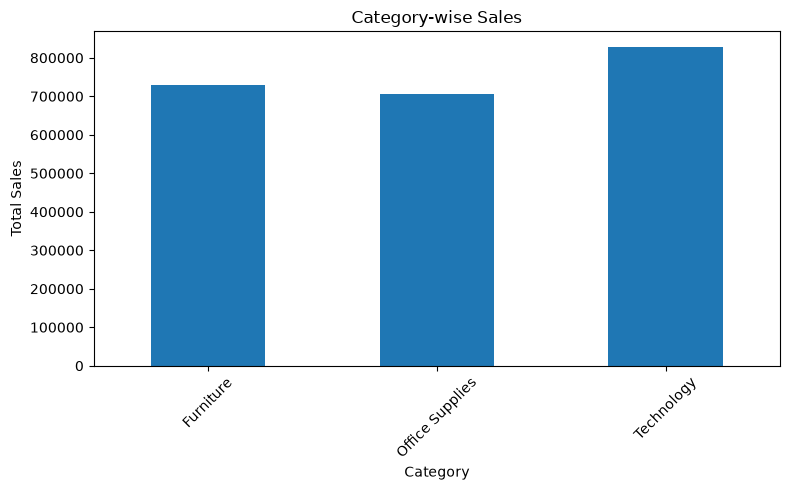

In [46]:
if category_col and sales_col:

    category_sales = df_clean.groupby(category_col)[sales_col].sum()

    plt.figure(figsize=(8, 5))
    category_sales.plot(kind='bar')

    plt.title("Category-wise Sales")
    plt.xlabel("Category")
    plt.ylabel("Total Sales")
    plt.xticks(rotation=45)
    plt.tight_layout()
    plt.show()

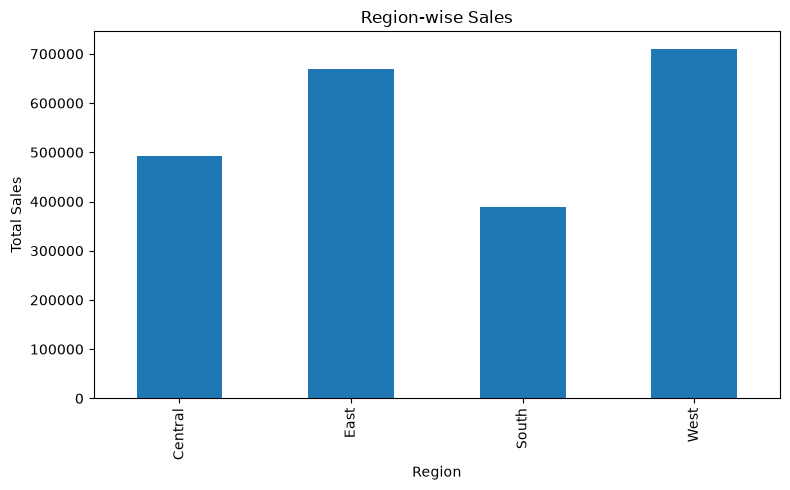

In [47]:
if region_col and sales_col:

    region_sales = df_clean.groupby(region_col)[sales_col].sum()

    plt.figure(figsize=(8, 5))
    region_sales.plot(kind='bar')

    plt.title("Region-wise Sales")
    plt.xlabel("Region")
    plt.ylabel("Total Sales")
    plt.tight_layout()
    plt.show()

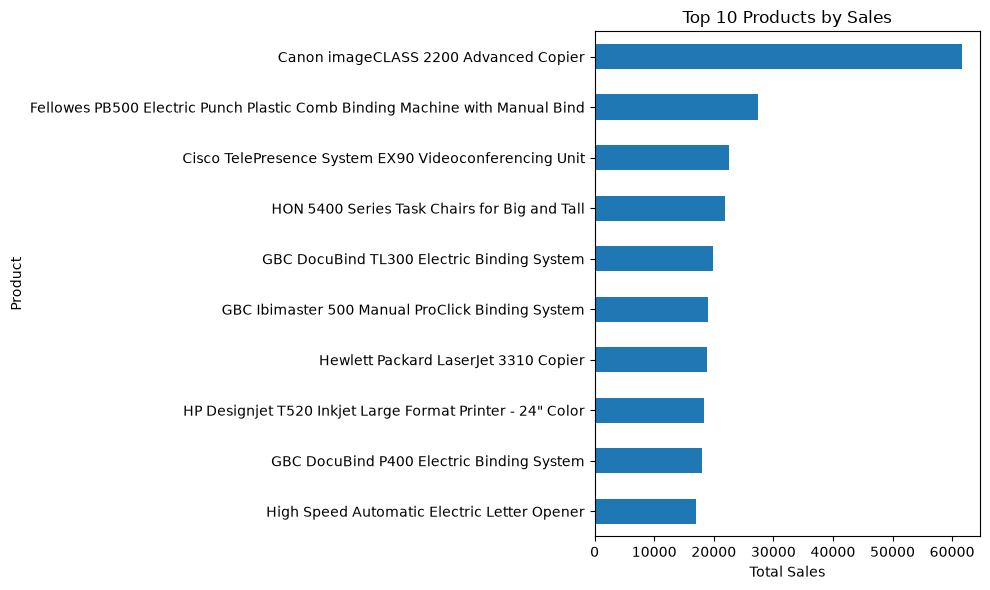

In [23]:
if product_col and sales_col:

    top_products = df_clean.groupby(
        product_col
    )[sales_col].sum().sort_values(ascending=False).head(10)

    plt.figure(figsize=(10, 6))
    top_products.sort_values().plot(kind='barh')

    plt.title("Top 10 Products by Sales")
    plt.xlabel("Total Sales")
    plt.ylabel("Product")
    plt.tight_layout()
    plt.show()

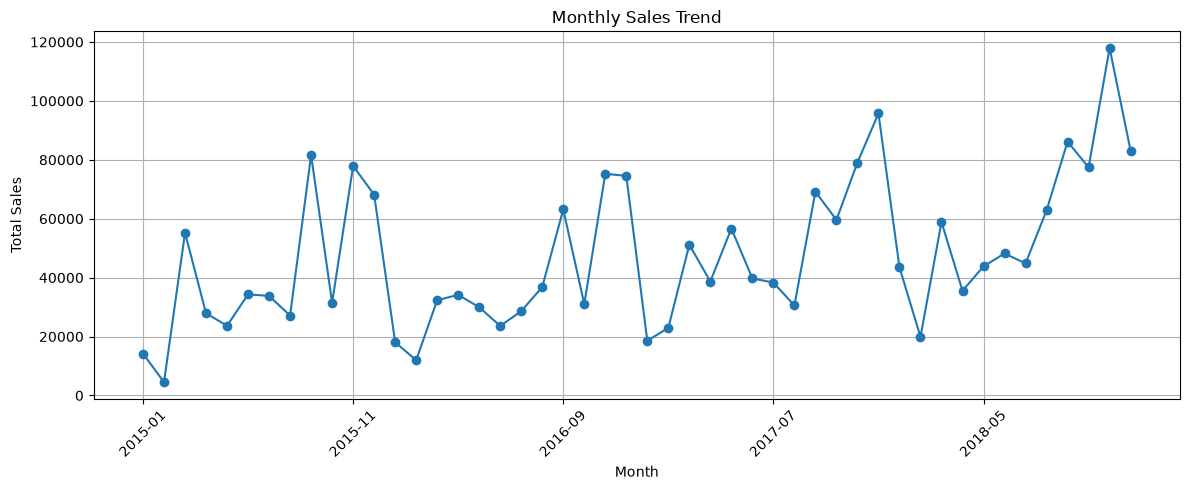

In [24]:
if date_col and sales_col:

    plt.figure(figsize=(12, 5))
    monthly_sales.plot(kind='line', marker='o')

    plt.title("Monthly Sales Trend")
    plt.xlabel("Month")
    plt.ylabel("Total Sales")
    plt.xticks(rotation=45)
    plt.grid(True)
    plt.tight_layout()
    plt.show()

In [26]:
if category_col and profit_col:

    category_profit = df_clean.groupby(category_col)[profit_col].sum()

    plt.figure(figsize=(8, 5))
    category_profit.plot(kind='bar')

    plt.title("Category-wise Profit")
    plt.xlabel("Category")
    plt.ylabel("Total Profit")
    plt.tight_layout()
    plt.show()

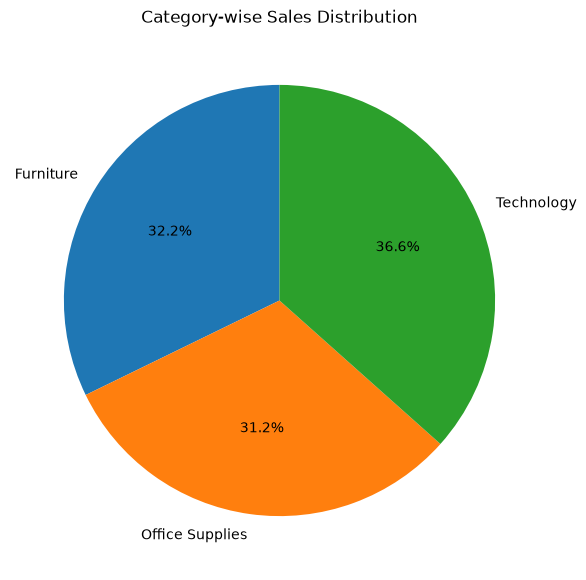

In [28]:
if category_col and sales_col:

    category_sales = df_clean.groupby(category_col)[sales_col].sum()

    plt.figure(figsize=(7, 7))

    category_sales.plot(
        kind='pie',
        autopct='%1.1f%%',
        startangle=90
    )

    plt.title("Category-wise Sales Distribution")
    plt.ylabel("")
    plt.show()

In [29]:
print("========== BUSINESS INSIGHTS ==========")

if sales_col:
    print("Total Sales:", round(df_clean[sales_col].sum(), 2))

if profit_col:
    print("Total Profit:", round(df_clean[profit_col].sum(), 2))

if quantity_col:
    print("Total Quantity:", df_clean[quantity_col].sum())

if category_col and sales_col:
    print(
        "Highest Sales Category:",
        df_clean.groupby(category_col)[sales_col].sum().idxmax()
    )

if region_col and sales_col:
    print(
        "Best Sales Region:",
        df_clean.groupby(region_col)[sales_col].sum().idxmax()
    )

if product_col and sales_col:
    print(
        "Highest Revenue Product:",
        df_clean.groupby(product_col)[sales_col].sum().idxmax()
    )

if date_col and sales_col:
    print(
        "Best Sales Month:",
        df_clean.groupby(df_clean[date_col].dt.month_name())[sales_col]
        .sum().idxmax()
    )

print("========================================")

========== BUSINESS INSIGHTS ==========
Total Sales: 2261536.78
Highest Sales Category: Technology
Best Sales Region: West
Highest Revenue Product: Canon imageCLASS 2200 Advanced Copier
Best Sales Month: November


In [30]:
print("Final Statistical Summary:")

display(df_clean.describe())

Final Statistical Summary:


,Row ID,Order Date,Ship Date,Postal Code,Sales
count,9800.000000,9800,9800,9800.000000,9800.000000
mean,4900.500000,2017-05-01 05:13:51.673469,2017-05-05 04:17:52.653061,55211.280918,230.769059
min,1.000000,2015-01-03 00:00:00,2015-01-07 00:00:00,0.000000,0.444000
25%,2450.750000,2016-05-24 00:00:00,2016-05-27 18:00:00,23223.000000,17.248000
50%,4900.500000,2017-06-26 00:00:00,2017-06-29 00:00:00,57551.000000,54.490000
75%,7350.250000,2018-05-15 00:00:00,2018-05-19 00:00:00,90008.000000,210.605000
max,9800.000000,2018-12-30 00:00:00,2019-01-05 00:00:00,99301.000000,22638.480000
std,2829.160653,NaN,NaN,32076.677954,626.651875


In [31]:
df_clean.to_csv('cleaned_sales_data.csv', index=False)

print("Cleaned Dataset Exported Successfully!")

Cleaned Dataset Exported Successfully!


In [32]:
if category_col and sales_col:

    category_sales.to_csv('category_sales_analysis.csv')

if region_col and sales_col:

    region_sales.to_csv('region_sales_analysis.csv')

if product_col and sales_col:

    top_products.to_csv('top_10_products.csv')

print("Analysis Results Exported Successfully!")

Analysis Results Exported Successfully!


In [33]:
print("======================================")
print(" SALES DATA ANALYSIS PROJECT")
print("======================================")
print("Dataset Cleaning: Completed")
print("Sales Analysis: Completed")
print("Data Visualization: Completed")
print("Business Insights: Generated")
print("Dataset Export: Completed")
print("======================================")
print("PROJECT ANALYSIS COMPLETED!")

 SALES DATA ANALYSIS PROJECT
Dataset Cleaning: Completed
Sales Analysis: Completed
Data Visualization: Completed
Business Insights: Generated
Dataset Export: Completed
PROJECT ANALYSIS COMPLETED!
